In [1]:
import os, math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.func import functional_call
import torchvision
from torchvision import transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
import pandas as pd

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = "outputs_part2"
os.makedirs(OUT, exist_ok=True)
os.makedirs("data", exist_ok=True)
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {DEVICE}")
if DEVICE.type == "cpu":
    print("No GPU found. Everything still runs, but full training will be slow. In Colab: Runtime > Change runtime type > GPU.")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda


## 1. Configuration

In [2]:
FAST_DEV_RUN = False   # True = tiny run (about a minute) to check the pipeline end to end

CFG = dict(
    emb_ch=64,
    # metric learners (ProtoNet and clustered prototypes)
    train_way=20, train_query=5, max_train_shot=5, p_multistyle=0.5,
    proto_steps=4000, proto_lr=1e-3,
    n_clusters=2, kmeans_iters=3,
    # MAML
    maml_way=5, maml_steps=3000, maml_meta_batch=4, maml_inner_lr=0.4,
    maml_inner_steps_train=1, maml_inner_steps_test=3, maml_outer_lr=1e-3,
    # pretrain baseline
    pre_steps=3000, pre_batch=128, pre_lr=1e-3,
    # evaluation
    eval_ways=(5, 20), eval_shots=(1, 5), eval_episodes=600, eval_query={5: 15, 20: 5},
    seed=0,
)

if FAST_DEV_RUN:
    CFG.update(proto_steps=20, maml_steps=5, pre_steps=20, eval_episodes=10)

for w in CFG["eval_ways"]:
    assert max(CFG["eval_shots"]) + CFG["eval_query"][w] <= 20
assert CFG["max_train_shot"] + CFG["train_query"] <= 20
CFG

{'emb_ch': 64,
 'train_way': 20,
 'train_query': 5,
 'max_train_shot': 5,
 'p_multistyle': 0.5,
 'proto_steps': 4000,
 'proto_lr': 0.001,
 'n_clusters': 2,
 'kmeans_iters': 3,
 'maml_way': 5,
 'maml_steps': 3000,
 'maml_meta_batch': 4,
 'maml_inner_lr': 0.4,
 'maml_inner_steps_train': 1,
 'maml_inner_steps_test': 3,
 'maml_outer_lr': 0.001,
 'pre_steps': 3000,
 'pre_batch': 128,
 'pre_lr': 0.001,
 'eval_ways': (5, 20),
 'eval_shots': (1, 5),
 'eval_episodes': 600,
 'eval_query': {5: 15, 20: 5},
 'seed': 0}

## 2. Data and task sampler
Each Omniglot character has 20 drawings by different people. A task samples `way` characters, then `shot` support and `n_query` query drawings from each. Supports and queries are always disjoint.

Loading Omniglot (first run takes a few minutes)...


100%|██████████| 9.46M/9.46M [00:00<00:00, 131MB/s]
100%|██████████| 6.46M/6.46M [00:00<00:00, 108MB/s]


meta-train (background alphabets): (964, 20, 1, 28, 28)
meta-test  (evaluation alphabets): (659, 20, 1, 28, 28)


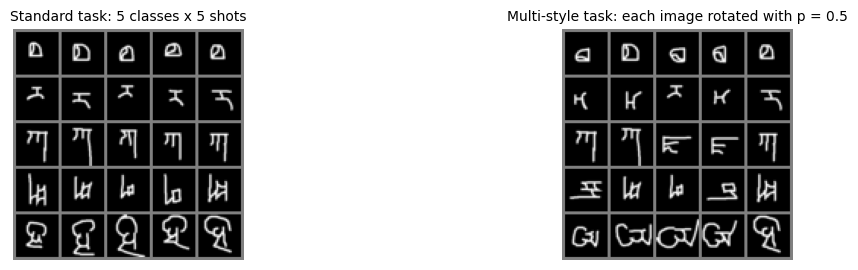

In [3]:
def load_omniglot(background):
    tf = transforms.Compose([transforms.Resize((28, 28)), transforms.ToTensor()])
    ds = torchvision.datasets.Omniglot(root="data", background=background, download=True, transform=tf)
    per_class = {}
    for i in range(len(ds)):
        x, y = ds[i]
        per_class.setdefault(y, []).append(1.0 - x)      # strokes bright, paper dark
    return torch.stack([torch.stack(per_class[c][:20]) for c in sorted(per_class)])   # [C, 20, 1, 28, 28]

cache = "data/omniglot28_gray.pt"
if os.path.exists(cache):
    X_train, X_test = torch.load(cache)
else:
    print("Loading Omniglot (first run takes a few minutes)...")
    X_train, X_test = load_omniglot(True), load_omniglot(False)
    torch.save((X_train, X_test), cache)
X_train, X_test = X_train.to(DEVICE), X_test.to(DEVICE)
print("meta-train (background alphabets):", tuple(X_train.shape))
print("meta-test  (evaluation alphabets):", tuple(X_test.shape))


def sample_task(X, way, shot, n_query, multistyle, gen=None):
    C, n_draw = X.shape[:2]
    cls = torch.randperm(C, generator=gen)[:way].to(X.device)
    perm = torch.argsort(torch.rand(way, n_draw, generator=gen), dim=1)[:, :shot + n_query].to(X.device)
    imgs = X[cls[:, None], perm]                                         # [way, shot+q, 1, 28, 28]
    if multistyle:
        rot = (torch.rand(way, shot + n_query, generator=gen) < 0.5).to(X.device)
        imgs = torch.where(rot[:, :, None, None, None], torch.rot90(imgs, 1, dims=(-2, -1)), imgs)
    xs = imgs[:, :shot].reshape(-1, *imgs.shape[2:])                    # class-major order
    xq = imgs[:, shot:].reshape(-1, *imgs.shape[2:])
    ys = torch.arange(way, device=X.device).repeat_interleave(shot)
    yq = torch.arange(way, device=X.device).repeat_interleave(n_query)
    return xs, ys, xq, yq


xs, ys, xq, yq = sample_task(X_test, 5, 5, 3, multistyle=True)
assert xs.shape == (25, 1, 28, 28) and xq.shape == (15, 1, 28, 28)
assert ys.tolist() == [c for c in range(5) for _ in range(5)]

fig, axes = plt.subplots(1, 2, figsize=(13, 3))
for ax, ms, title in zip(axes, [False, True], ["Standard task: 5 classes x 5 shots", "Multi-style task: each image rotated with p = 0.5"]):
    g = torch.Generator().manual_seed(3)
    s, _, _, _ = sample_task(X_test, 5, 5, 1, multistyle=ms, gen=g)
    ax.imshow(make_grid(s.cpu(), nrow=5, padding=2, pad_value=0.5)[0], cmap="gray")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.show()

## 3. Models

### 3.1 Backbone
The standard Conv-4 used in the few-shot literature (Vinyals et al., 2016; Snell et al., 2017; Finn et al., 2017), with GroupNorm instead of BatchNorm so that every method is non-transductive: a query's prediction never depends on the other queries in the batch.

In [4]:
def conv4_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.GroupNorm(8, cout), nn.ReLU(), nn.MaxPool2d(2))

class Conv4(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net = nn.Sequential(conv4_block(1, ch), conv4_block(ch, ch), conv4_block(ch, ch), conv4_block(ch, ch),
                                 nn.Flatten())                    # 28 -> 14 -> 7 -> 3 -> 1, output: ch
        self.out_dim = ch

    def forward(self, x):
        return self.net(x)

### 3.2 Prototypes: single mean vs clustered
For each class the clustered head:
1. picks `M` starting points by farthest-point selection (the support farthest from the class mean, then the support farthest from that, and so on), which is deterministic and order invariant;
2. refines them with a few steps of differentiable soft k-means, with a temperature scaled to the spread of the support set;
3. scores a query by the log of a mixture over centroids, weighted by how many supports each centroid holds.

Squared distances are computed directly rather than with `cdist`, since the gradient of a Euclidean distance at zero is undefined and a one-shot centroid sits exactly on its support point.

In [5]:
def by_class(z, way):
    return z.reshape(way, -1, z.shape[-1])                      # [way, k, d]

def proto_logits(zs, zq, way):
    P = by_class(zs, way).mean(1)                                 # [way, d]
    return -((zq[:, None] - P[None]) ** 2).sum(-1)                # [Q, way]

def farthest_point_init(H, M):
    # H: [N, k, d] -> M starting centroids per class, [N, M, d]
    idx = torch.arange(H.shape[0], device=H.device)
    d_ref = ((H - H.mean(1, keepdim=True)) ** 2).sum(-1)          # [N, k]
    cents, d_sel = [], None
    for _ in range(M):
        score = d_ref if d_sel is None else d_sel
        c = H[idx, score.argmax(1)]                               # [N, d]
        cents.append(c)
        dc = ((H - c[:, None]) ** 2).sum(-1)
        d_sel = dc if d_sel is None else torch.minimum(d_sel, dc)
    return torch.stack(cents, dim=1)

def soft_kmeans(H, init, iters, tau, eps=1e-3):
    mu, mass = init, None
    for _ in range(iters):
        d2 = ((H[:, :, None] - mu[:, None]) ** 2).sum(-1)         # [N, k, M]
        a = torch.softmax(-d2 / tau, dim=-1)
        mass = a.sum(1)                                           # [N, M]
        mu = (a.transpose(1, 2) @ H + eps * mu) / (mass[..., None] + eps)
    return mu, mass

class ClusteredProtoHead(nn.Module):
    def __init__(self, n_clusters, iters):
        super().__init__()
        self.M, self.iters = n_clusters, iters
        self.log_tau = nn.Parameter(torch.zeros(()))

    def forward(self, zs, zq, way):
        H = by_class(zs, way)
        spread = ((H - H.mean(1, keepdim=True)) ** 2).sum(-1).mean().detach().clamp_min(1e-6)
        mu, mass = soft_kmeans(H, farthest_point_init(H, self.M), self.iters, self.log_tau.exp() * spread)
        log_w = torch.log(mass / H.shape[1] + 1e-8)                # mixture weights, [N, M]
        d2 = ((zq[:, None, None] - mu[None]) ** 2).sum(-1)        # [Q, N, M]
        return torch.logsumexp(-d2 + log_w[None], dim=-1), mu, mass

### 3.3 The three learners

In [6]:
class MetricLearner(nn.Module):
    # kind = "proto" (Prototypical Network) or "clustered" (SCACM-Proto)
    def __init__(self, kind, cfg):
        super().__init__()
        self.enc = Conv4(cfg["emb_ch"])
        self.head = ClusteredProtoHead(cfg["n_clusters"], cfg["kmeans_iters"]) if kind == "clustered" else None

    def logits(self, xs, ys, xq, way):
        z = self.enc(torch.cat([xs, xq]))
        zs, zq = z[:len(xs)], z[len(xs):]
        return proto_logits(zs, zq, way) if self.head is None else self.head(zs, zq, way)[0]


class PretrainBaseline(nn.Module):
    # ordinary classifier over all training characters; at test time cosine nearest class mean on frozen features
    def __init__(self, cfg, n_classes):
        super().__init__()
        self.enc = Conv4(cfg["emb_ch"])
        self.fc = nn.Linear(self.enc.out_dim, n_classes)

    def logits(self, xs, ys, xq, way):
        z = F.normalize(self.enc(torch.cat([xs, xq])), dim=-1)
        return proto_logits(z[:len(xs)], z[len(xs):], way)


class MAML(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(Conv4(cfg["emb_ch"]), nn.Linear(cfg["emb_ch"], cfg["maml_way"]))

    def adapt(self, xs, ys, steps, lr, create_graph):
        params = dict(self.net.named_parameters())
        for _ in range(steps):
            loss = F.cross_entropy(functional_call(self.net, params, (xs,)), ys)
            grads = torch.autograd.grad(loss, list(params.values()), create_graph=create_graph)
            params = {name: p - lr * g for (name, p), g in zip(params.items(), grads)}
        return params

    def logits(self, xs, ys, xq, steps, lr, create_graph):
        return functional_call(self.net, self.adapt(xs, ys, steps, lr, create_graph), (xq,))

### 3.4 Unit tests
Run before any training so wiring errors show up immediately.

In [7]:
torch.manual_seed(0)

# 1) With one shot the clustered head must give exactly the ProtoNet logits
head = ClusteredProtoHead(CFG["n_clusters"], CFG["kmeans_iters"])
zs, zq = torch.randn(5 * 1, 64), torch.randn(10, 64)
assert torch.allclose(head(zs, zq, 5)[0], proto_logits(zs, zq, 5), atol=1e-4), "1-shot clustered != ProtoNet"

# 2) Two well separated groups inside one class must be found as two centroids
a, b = torch.randn(1, 64), torch.randn(1, 64) + 20
H = torch.cat([a + 0.01 * torch.randn(3, 64), b + 0.01 * torch.randn(3, 64)]).reshape(1, 6, 64)
mu, mass = soft_kmeans(H, farthest_point_init(H, 2), 3, tau=1.0)
assert torch.allclose(mass, torch.tensor([[3.0, 3.0]]), atol=1e-2), mass
assert min((mu[0, 0] - a).norm(), (mu[0, 1] - a).norm()) < 0.5 and min((mu[0, 0] - b).norm(), (mu[0, 1] - b).norm()) < 0.5

# 3) Every learner produces [n_query, way] logits and finite gradients
xs, ys, xq, yq = sample_task(X_train, 5, 2, 3, multistyle=True)
for kind in ["proto", "clustered"]:
    m = MetricLearner(kind, CFG).to(DEVICE)
    out = m.logits(xs, ys, xq, 5)
    assert out.shape == (15, 5)
    F.cross_entropy(out, yq).backward()
    assert all(torch.isfinite(p.grad).all() for p in m.parameters() if p.grad is not None)
m = PretrainBaseline(CFG, X_train.shape[0]).to(DEVICE)
assert m.logits(xs, ys, xq, 5).shape == (15, 5)
m = MAML(CFG).to(DEVICE)
out = m.logits(xs, ys, xq, 1, CFG["maml_inner_lr"], create_graph=True)
assert out.shape == (15, 5)
F.cross_entropy(out, yq).backward()
assert all(torch.isfinite(p.grad).all() for p in m.parameters())
print("all unit tests passed")

all unit tests passed


## 4. Training
Every learner sees the same task distribution: shots drawn uniformly from 1 to 5, and half the tasks multi-style. Metric learners train on 20-way tasks (training with more ways than at test time is standard for Prototypical Networks). MAML trains on 5-way tasks because its output layer has a fixed size, so it is evaluated on 5-way tasks only.

In [8]:
def smooth_log(hist, step, loss, acc, every):
    if step == 1 or step % every == 0:
        hist.append(dict(step=step, loss=loss, acc=acc))

def train_metric(kind, cfg, seed):
    set_seed(seed)
    model = MetricLearner(kind, cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["proto_lr"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["proto_steps"])
    hist, every, t0 = [], max(1, cfg["proto_steps"] // 50), time.time()
    for step in range(1, cfg["proto_steps"] + 1):
        shot = random.randint(1, cfg["max_train_shot"])
        ms = random.random() < cfg["p_multistyle"]
        xs, ys, xq, yq = sample_task(X_train, cfg["train_way"], shot, cfg["train_query"], ms)
        logits = model.logits(xs, ys, xq, cfg["train_way"])
        loss = F.cross_entropy(logits, yq)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()
        smooth_log(hist, step, loss.item(), (logits.argmax(1) == yq).float().mean().item(), every)
    print(f"  done in {time.time() - t0:.0f}s | last train acc {hist[-1]['acc']:.3f}")
    return model, pd.DataFrame(hist)

def train_maml(cfg, seed):
    set_seed(seed)
    model = MAML(cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["maml_outer_lr"])
    hist, every, t0 = [], max(1, cfg["maml_steps"] // 50), time.time()
    for step in range(1, cfg["maml_steps"] + 1):
        opt.zero_grad(set_to_none=True)
        tot_loss, tot_acc = 0.0, 0.0
        for _ in range(cfg["maml_meta_batch"]):
            shot = random.randint(1, cfg["max_train_shot"])
            ms = random.random() < cfg["p_multistyle"]
            xs, ys, xq, yq = sample_task(X_train, cfg["maml_way"], shot, cfg["train_query"], ms)
            logits = model.logits(xs, ys, xq, cfg["maml_inner_steps_train"], cfg["maml_inner_lr"], create_graph=True)
            loss = F.cross_entropy(logits, yq) / cfg["maml_meta_batch"]
            loss.backward()                                  # second-order meta-gradient
            tot_loss += loss.item()
            tot_acc += (logits.argmax(1) == yq).float().mean().item() / cfg["maml_meta_batch"]
        nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        opt.step()
        smooth_log(hist, step, tot_loss, tot_acc, every)
    print(f"  done in {time.time() - t0:.0f}s | last train acc {hist[-1]['acc']:.3f}")
    return model, pd.DataFrame(hist)

def train_pretrain(cfg, seed):
    set_seed(seed)
    C = X_train.shape[0]
    model = PretrainBaseline(cfg, C).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["pre_lr"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["pre_steps"])
    hist, every, t0 = [], max(1, cfg["pre_steps"] // 50), time.time()
    for step in range(1, cfg["pre_steps"] + 1):
        cls = torch.randint(0, C, (cfg["pre_batch"],), device=DEVICE)
        j = torch.randint(0, X_train.shape[1], (cfg["pre_batch"],), device=DEVICE)
        x = X_train[cls, j]
        if random.random() < cfg["p_multistyle"]:
            rot = torch.rand(cfg["pre_batch"], device=DEVICE) < 0.5
            x = torch.where(rot[:, None, None, None], torch.rot90(x, 1, dims=(-2, -1)), x)
        logits = model.fc(model.enc(x))
        loss = F.cross_entropy(logits, cls)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()
        smooth_log(hist, step, loss.item(), (logits.argmax(1) == cls).float().mean().item(), every)
    print(f"  done in {time.time() - t0:.0f}s | last train acc {hist[-1]['acc']:.3f}")
    return model, pd.DataFrame(hist)


METHODS = ["Pretrain + NC", "MAML", "ProtoNet", "Clustered prototypes"]
models, curves = {}, {}
seed = CFG["seed"]
print("=== Pretrain + nearest centroid ===");  models["Pretrain + NC"], curves["Pretrain + NC"] = train_pretrain(CFG, seed)
print("=== MAML ===");                         models["MAML"], curves["MAML"] = train_maml(CFG, seed)
print("=== ProtoNet ===");                     models["ProtoNet"], curves["ProtoNet"] = train_metric("proto", CFG, seed)
print("=== Clustered prototypes ===");         models["Clustered prototypes"], curves["Clustered prototypes"] = train_metric("clustered", CFG, seed)
for name, m in models.items():
    tag = name.lower().replace(" ", "_").replace("+", "plus")
    torch.save(m.state_dict(), f"{OUT}/{tag}_seed{seed}.pt")

=== Pretrain + nearest centroid ===
  done in 20s | last train acc 0.727
=== MAML ===
  done in 205s | last train acc 0.940
=== ProtoNet ===
  done in 38s | last train acc 0.950
=== Clustered prototypes ===
  done in 45s | last train acc 0.950


## 5. Evaluation
Each setting uses its own fixed random seed, so all methods are tested on identical tasks and the comparison is paired.

In [9]:
def task_logits(name, model, xs, ys, xq, way, cfg):
    if name == "MAML":
        with torch.enable_grad():   # MAML needs gradients for its inner loop even at test time
            return model.logits(xs, ys, xq, cfg["maml_inner_steps_test"], cfg["maml_inner_lr"], create_graph=False).detach()
    with torch.no_grad():
        return model.logits(xs, ys, xq, way)

def evaluate(name, model, way, shot, multistyle, cfg, seed=1234):
    model.eval()
    g = torch.Generator().manual_seed(seed + 100 * way + 10 * shot + int(multistyle))
    accs = []
    for _ in range(cfg["eval_episodes"]):
        xs, ys, xq, yq = sample_task(X_test, way, shot, cfg["eval_query"][way], multistyle, gen=g)
        accs.append((task_logits(name, model, xs, ys, xq, way, cfg).argmax(1) == yq).float().mean().item())
    a = np.array(accs) * 100
    return a.mean(), 1.96 * a.std(ddof=1) / math.sqrt(len(a)), a

rows, per_task = [], {}
for cond in ["standard", "multi-style"]:
    for way in CFG["eval_ways"]:
        for shot in CFG["eval_shots"]:
            for name in METHODS:
                if name == "MAML" and way != CFG["maml_way"]:
                    continue
                mean, ci, a = evaluate(name, models[name], way, shot, cond == "multi-style", CFG)
                rows.append(dict(condition=cond, way=way, shot=shot, method=name, acc=mean, ci95=ci))
                per_task[(cond, way, shot, name)] = a
            print(f"{cond:11s} {way:2d}-way {shot}-shot | " +
                  " | ".join(f"{r['method']}: {r['acc']:.2f}" for r in rows if (r["condition"], r["way"], r["shot"]) == (cond, way, shot)))

res = pd.DataFrame(rows)
res.to_csv(f"{OUT}/results.csv", index=False)

standard     5-way 1-shot | Pretrain + NC: 94.15 | MAML: 61.67 | ProtoNet: 95.41 | Clustered prototypes: 95.32
standard     5-way 5-shot | Pretrain + NC: 98.37 | MAML: 35.68 | ProtoNet: 98.59 | Clustered prototypes: 98.74
standard    20-way 1-shot | Pretrain + NC: 83.93 | ProtoNet: 86.18 | Clustered prototypes: 86.74
standard    20-way 5-shot | Pretrain + NC: 95.05 | ProtoNet: 95.95 | Clustered prototypes: 96.25
multi-style  5-way 1-shot | Pretrain + NC: 86.49 | MAML: 55.11 | ProtoNet: 90.46 | Clustered prototypes: 90.60
multi-style  5-way 5-shot | Pretrain + NC: 96.30 | MAML: 27.50 | ProtoNet: 97.38 | Clustered prototypes: 97.59
multi-style 20-way 1-shot | Pretrain + NC: 70.48 | ProtoNet: 76.10 | Clustered prototypes: 75.86
multi-style 20-way 5-shot | Pretrain + NC: 88.71 | ProtoNet: 91.77 | Clustered prototypes: 92.24


## 6. Results

In [10]:
res["setting"] = res["way"].astype(str) + "-way " + res["shot"].astype(str) + "-shot"
res["acc_ci"] = res["acc"].map("{:.2f}".format) + " ± " + res["ci95"].map("{:.2f}".format)
table = res.pivot_table(index=["condition", "setting"], columns="method", values="acc_ci", aggfunc="first")
table = table[[m for m in METHODS if m in table.columns]].fillna("n/a")
display(table)

# paired comparison: clustered minus ProtoNet on the same tasks
paired = []
for cond in ["standard", "multi-style"]:
    for way in CFG["eval_ways"]:
        for shot in CFG["eval_shots"]:
            d = per_task[(cond, way, shot, "Clustered prototypes")] - per_task[(cond, way, shot, "ProtoNet")]
            paired.append(dict(condition=cond, setting=f"{way}-way {shot}-shot", gain=d.mean(),
                               ci95=1.96 * d.std(ddof=1) / math.sqrt(len(d))))
paired = pd.DataFrame(paired)
print("Clustered prototypes minus ProtoNet (accuracy points, paired over identical tasks):")
display(paired.round(2))

method                    Pretrain + NC          MAML      ProtoNet  \
condition   setting                                                   
multi-style 20-way 1-shot  70.48 ± 0.49           n/a  76.10 ± 0.50   
            20-way 5-shot  88.71 ± 0.31           n/a  91.77 ± 0.26   
            5-way 1-shot   86.49 ± 0.66  55.11 ± 2.32  90.46 ± 0.59   
            5-way 5-shot   96.30 ± 0.28  27.50 ± 1.21  97.38 ± 0.23   
standard    20-way 1-shot  83.93 ± 0.42           n/a  86.18 ± 0.41   
            20-way 5-shot  95.05 ± 0.21           n/a  95.95 ± 0.19   
            5-way 1-shot   94.15 ± 0.45  61.67 ± 2.59  95.41 ± 0.40   
            5-way 5-shot   98.37 ± 0.16  35.68 ± 1.95  98.59 ± 0.14   

method                    Clustered prototypes  
condition   setting                             
multi-style 20-way 1-shot         75.86 ± 0.49  
            20-way 5-shot         92.24 ± 0.27  
            5-way 1-shot          90.60 ± 0.59  
            5-way 5-shot          97.59 ± 0.22  
standard    20-way 1-shot         86.74 ± 0.39  
            20-way 5-shot         96.25 ± 0.18  
            5-way 1-shot          95.32 ± 0.40  
            5-way 5-shot          98.74 ± 0.14

Clustered prototypes minus ProtoNet (accuracy points, paired over identical tasks):


,condition,setting,gain,ci95
0,standard,5-way 1-shot,-0.10,0.27
1,standard,5-way 5-shot,0.16,0.11
2,standard,20-way 1-shot,0.56,0.29
3,standard,20-way 5-shot,0.30,0.16
4,multi-style,5-way 1-shot,0.14,0.37
5,multi-style,5-way 5-shot,0.21,0.15
6,multi-style,20-way 1-shot,-0.24,0.37
7,multi-style,20-way 5-shot,0.47,0.21


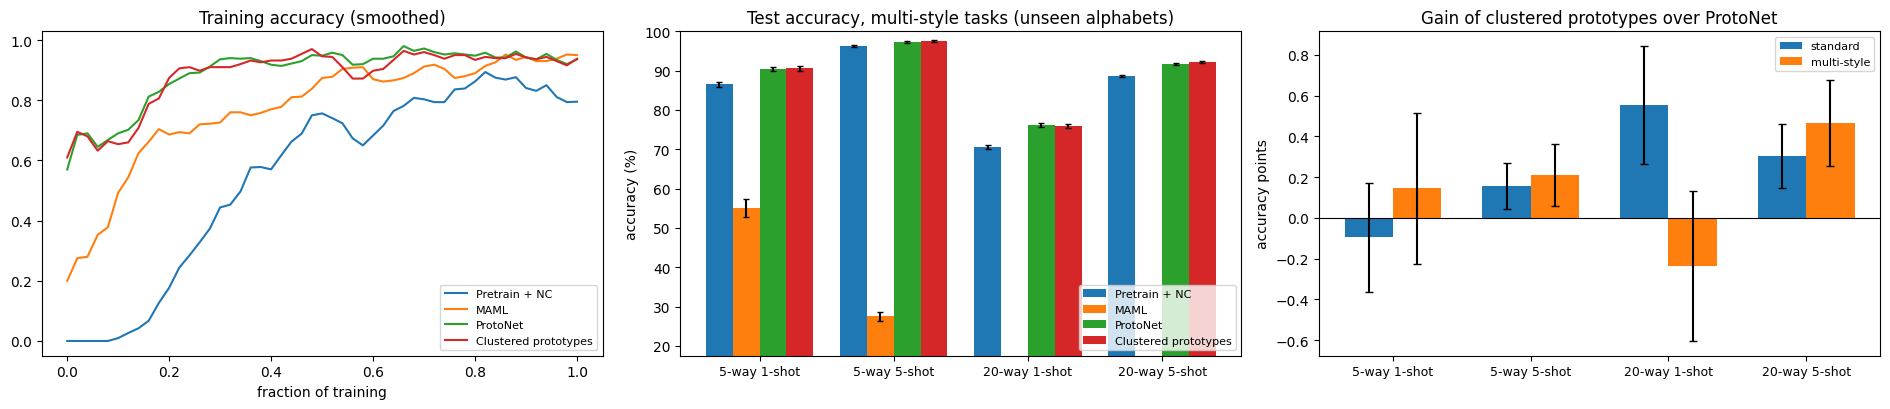

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))

for name in METHODS:
    h = curves[name]
    axes[0].plot(h["step"] / h["step"].max(), h["acc"].rolling(5, min_periods=1).mean(), label=name)
axes[0].set_title("Training accuracy (smoothed)"); axes[0].set_xlabel("fraction of training"); axes[0].legend(fontsize=8)

settings = list(dict.fromkeys(res["setting"]))
width = 0.2
for ax, cond in zip(axes[1:2], ["multi-style"]):
    for i, name in enumerate(METHODS):
        sub = res[(res.condition == cond) & (res.method == name)].set_index("setting").reindex(settings)
        ax.bar(np.arange(len(settings)) + (i - 1.5) * width, sub["acc"], width, yerr=sub["ci95"], label=name, capsize=2)
    ax.set_xticks(np.arange(len(settings))); ax.set_xticklabels(settings, fontsize=9)
    lo = np.nanmin(res[res.condition == cond]["acc"])
    ax.set_ylim(max(0, lo - 10), 100)
    ax.set_title(f"Test accuracy, {cond} tasks (unseen alphabets)"); ax.set_ylabel("accuracy (%)")
    ax.legend(fontsize=8)

x = np.arange(len(settings))
for j, cond in enumerate(["standard", "multi-style"]):
    sub = paired[paired.condition == cond].set_index("setting").reindex(settings)
    axes[2].bar(x + (j - 0.5) * 0.35, sub["gain"], 0.35, yerr=sub["ci95"], capsize=3, label=cond)
axes[2].axhline(0, c="black", lw=0.8)
axes[2].set_xticks(x); axes[2].set_xticklabels(settings, fontsize=9)
axes[2].set_title("Gain of clustered prototypes over ProtoNet"); axes[2].set_ylabel("accuracy points"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/results.png", dpi=150, bbox_inches="tight")
plt.show()

### Looking inside one class
One test character with 10 supports in two styles. The plot projects embeddings to 2-D with PCA and shows where the single mean prototype lands compared with the two cluster centroids. If the hypothesis holds, the mean falls between the two groups while the centroids sit inside them.

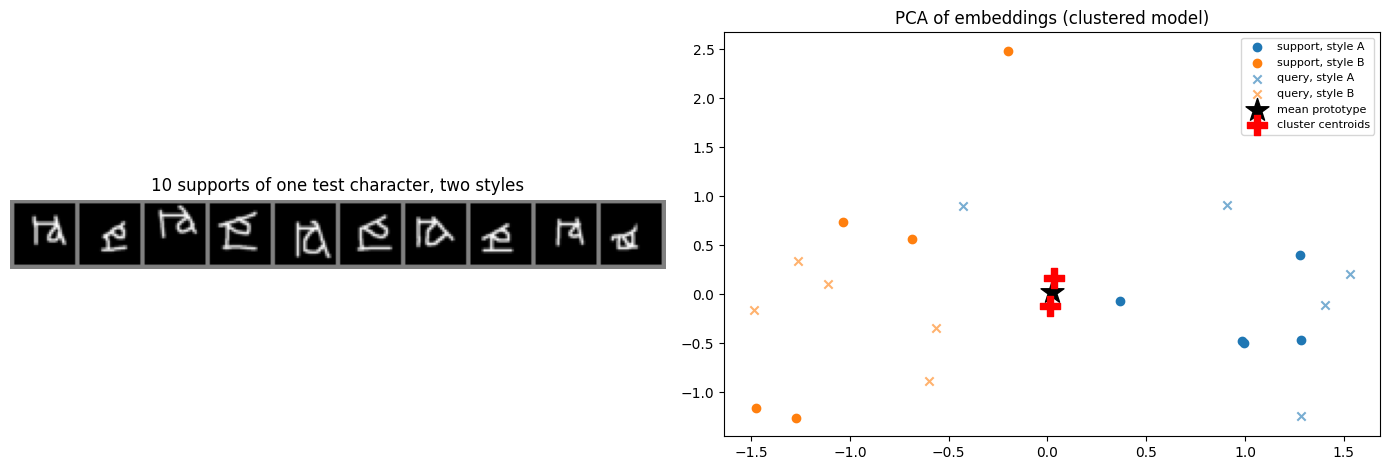

cluster masses (supports per centroid): [4.99, 5.01]


In [12]:
model = models["Clustered prototypes"].eval()
c = 7
imgs = X_test[c]                                                  # [20, 1, 28, 28]
styles = torch.arange(20, device=DEVICE) % 2 == 1                 # alternate the two styles
imgs = torch.where(styles[:, None, None, None], torch.rot90(imgs, 1, dims=(-2, -1)), imgs)
with torch.no_grad():
    z = model.enc(imgs)
    zs, zq = z[:10], z[10:]
    _, mu, mass = model.head(zs, zq, 1)
    mean_proto = zs.mean(0, keepdim=True)

pts = torch.cat([zs, zq, mean_proto, mu[0]])
pts = pts - pts.mean(0, keepdim=True)
_, _, V = torch.linalg.svd(pts, full_matrices=False)
p2 = (pts @ V[:2].T).cpu().numpy()
st = styles.cpu().numpy()

fig = plt.figure(figsize=(14, 4.8))
ax0 = fig.add_subplot(1, 2, 1)
ax0.imshow(make_grid(imgs[:10].cpu(), nrow=10, padding=2, pad_value=0.5)[0], cmap="gray")
ax0.set_title("10 supports of one test character, two styles"); ax0.axis("off")
ax = fig.add_subplot(1, 2, 2)
ax.scatter(p2[:10][~st[:10], 0], p2[:10][~st[:10], 1], c="tab:blue", label="support, style A")
ax.scatter(p2[:10][st[:10], 0], p2[:10][st[:10], 1], c="tab:orange", label="support, style B")
ax.scatter(p2[10:20][~st[10:], 0], p2[10:20][~st[10:], 1], c="tab:blue", marker="x", alpha=0.6, label="query, style A")
ax.scatter(p2[10:20][st[10:], 0], p2[10:20][st[10:], 1], c="tab:orange", marker="x", alpha=0.6, label="query, style B")
ax.scatter(p2[20, 0], p2[20, 1], c="black", marker="*", s=300, label="mean prototype")
ax.scatter(p2[21:, 0], p2[21:, 1], c="red", marker="P", s=200, label="cluster centroids")
ax.set_title("PCA of embeddings (clustered model)"); ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig(f"{OUT}/inside_one_class.png", dpi=150, bbox_inches="tight")
plt.show()
print("cluster masses (supports per centroid):", [round(v, 2) for v in mass[0].tolist()])

In [13]:
# Plain-language summary generated from the numbers above
for _, r in paired.iterrows():
    sig = "inside the 95% interval, not a real difference" if abs(r.gain) <= r.ci95 else ("better" if r.gain > 0 else "worse")
    print(f"{r.condition:11s} {r.setting}: clustered vs ProtoNet {r.gain:+.2f} +/- {r.ci95:.2f} points -> {sig}")
if FAST_DEV_RUN:
    print("\nFAST_DEV_RUN is on: these numbers come from a few training steps and say nothing about the methods.")

standard    5-way 1-shot: clustered vs ProtoNet -0.10 +/- 0.27 points -> inside the 95% interval, not a real difference
standard    5-way 5-shot: clustered vs ProtoNet +0.16 +/- 0.11 points -> better
standard    20-way 1-shot: clustered vs ProtoNet +0.56 +/- 0.29 points -> better
standard    20-way 5-shot: clustered vs ProtoNet +0.30 +/- 0.16 points -> better
multi-style 5-way 1-shot: clustered vs ProtoNet +0.14 +/- 0.37 points -> inside the 95% interval, not a real difference
multi-style 5-way 5-shot: clustered vs ProtoNet +0.21 +/- 0.15 points -> better
multi-style 20-way 1-shot: clustered vs ProtoNet -0.24 +/- 0.37 points -> inside the 95% interval, not a real difference
multi-style 20-way 5-shot: clustered vs ProtoNet +0.47 +/- 0.21 points -> better
